In [148]:
import pandas as pd
import numpy as np

In [149]:
train = pd.read_csv('CMAPSSData/train_FD003.txt', sep='\s+', header=None)
test = pd.read_csv('CMAPSSData/test_FD003.txt', sep='\s+', header=None)
rul = pd.read_csv('CMAPSSData/RUL_FD003.txt', sep='\s+', header=None)

In [150]:
columns_to_remove = [5, 9, 10, 14, 20, 22, 23]

train = train.drop(columns=columns_to_remove)
test = test.drop(columns=columns_to_remove)

In [151]:
train = train.rename(columns={0 : 'engine', 1 : 'cycle'})
train.head(10)

,engine,cycle,2,3,4,6,7,8,11,12,13,15,16,17,18,19,21,24,25
0,1,1,-0.0005,0.0004,100.0,642.36,1583.23,1396.84,553.97,2387.96,9062.17,47.30,522.31,2388.01,8145.32,8.4246,391,39.11,23.3537
1,1,2,0.0008,-0.0003,100.0,642.50,1584.69,1396.89,554.55,2388.00,9061.78,47.23,522.42,2388.03,8152.85,8.4403,392,38.99,23.4491
2,1,3,-0.0014,-0.0002,100.0,642.18,1582.35,1405.61,554.43,2388.03,9070.23,47.22,522.03,2388.00,8150.17,8.3901,391,38.85,23.3669
3,1,4,-0.0020,0.0001,100.0,642.92,1585.61,1392.27,555.21,2388.00,9064.57,47.24,522.49,2388.08,8146.56,8.3878,392,38.96,23.2951
4,1,5,0.0016,0.0000,100.0,641.68,1588.63,1397.65,554.74,2388.04,9076.14,47.15,522.58,2388.03,8147.80,8.3869,392,39.14,23.4583
5,1,6,0.0011,-0.0005,100.0,642.24,1584.09,1400.01,554.75,2388.00,9074.98,47.07,522.42,2388.02,8144.92,8.4152,393,38.92,23.4281
6,1,7,-0.0038,0.0002,100.0,642.58,1585.61,1401.09,554.58,2388.04,9074.65,47.38,522.46,2388.02,8147.05,8.3842,391,38.84,23.4087
7,1,8,-0.0007,-0.0005,100.0,642.32,1588.32,1397.08,554.85,2388.06,9063.54,47.31,522.10,2387.97,8157.34,8.4190,391,39.05,23.4590
8,1,9,-0.0026,0.0000,100.0,641.64,1587.81,1406.51,554.13,2388.04,9067.20,47.31,521.83,2388.01,8147.20,8.4091,392,38.99,23.4693
9,1,10,0.0019,-0.0002,100.0,642.42,1587.39,1402.25,554.78,2387.99,9070.04,47.35,521.96,2387.99,8152.86,8.3987,391,38.94,23.4781


In [152]:
test = test.rename(columns={0 : 'engine', 1 : 'cycle'})

In [153]:
train['rul'] = np.minimum(125, train.groupby('engine')['cycle'].transform('max') - train['cycle'])

In [154]:
# define feature columns
feature_cols = [2, 3, 4, 6, 7, 8, 11, 12, 13, 15, 16, 17, 18, 19, 21, 24, 25]

In [155]:
def create_feature_df(data):

    feature_df = pd.DataFrame()

    for engine_id, engine_df in data.groupby('engine'):
        features = {}
        df = engine_df[feature_cols]

        for feature in df.columns:
            readings = df[feature]
            features[f'{feature}_mean'] = readings.mean()
            features[f'{feature}_std'] = readings.std()
            features[f'{feature}_min'] = readings.min()
            features[f'{feature}_max'] = readings.max()
            features[f'{feature}_median'] = readings.median()

        features = pd.DataFrame([features])

        if engine_id == 0:
            feature_df = features
            continue
        feature_df = pd.concat([feature_df, features], ignore_index=True)

    return feature_df




In [156]:
train = create_feature_df(train)
test = create_feature_df(test)

In [157]:
from sklearn.preprocessing import StandardScaler

In [158]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(train)
test_scaled = scaler.transform(test)

In [159]:
type(train)

pandas.core.frame.DataFrame

In [160]:
from sklearn.cluster import KMeans

kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=20
)

clusters = kmeans.fit_predict(train)
train['cluster'] = clusters

In [161]:
train['cluster'].value_counts()

cluster
0    61
1    39
Name: count, dtype: int64

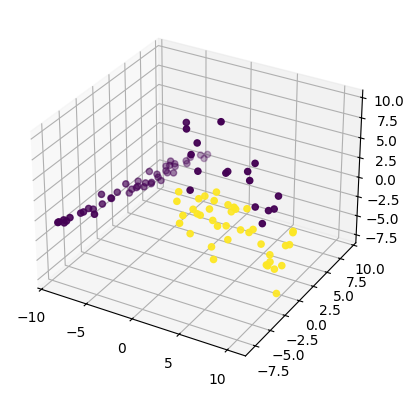

In [164]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components=3)

X_pca = pca.fit_transform(X_scaled)

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    X_pca[:, 2],
    c=clusters
)

In [165]:
print(pca.explained_variance_ratio_)
print(pca.explained_variance_ratio_.sum())

[0.48817567 0.15335187 0.09645053]
0.7379780759113213


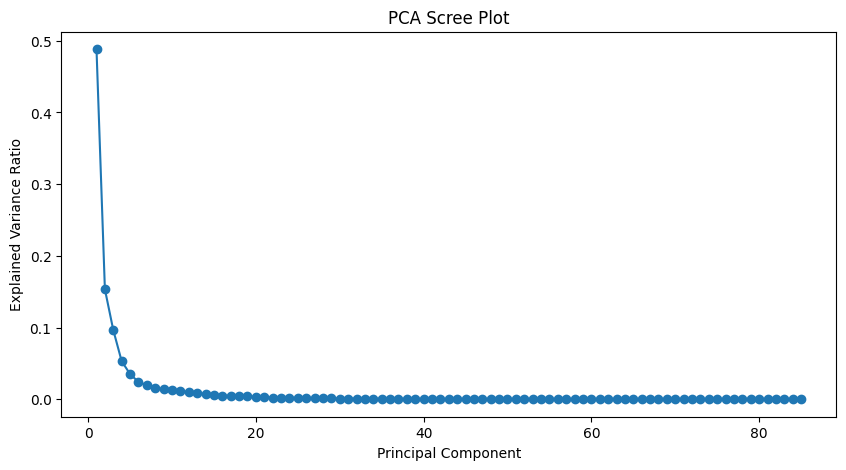

In [166]:
pca = PCA()

pca.fit(X_scaled)

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(pca.explained_variance_ratio_) + 1),
    pca.explained_variance_ratio_,
    marker="o"
)

plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")
plt.title("PCA Scree Plot")

plt.show()